# Arbitrage on real-world model markets

Figures 1–4 of the paper on Terminal-Bench 2.0 and 4.0, LiveCodeBench and DeepSWE.

In [1]:
import os, json, warnings

warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from utils import *

## Figure 1: The cost of a given performance target varies by more than an order of magnitude across the market.
Expected total cost for each model to reach a 40% (top) and a 70% (bottom) solve rate on
Terminal-Bench 2.0. For each model, we give every
query the same budget, compute the probability that repeated sampling solves it before the budget is
exhausted, and increase the budget until the average solve rate reaches the target. 

28 systems x 2 targets, 88 tasks


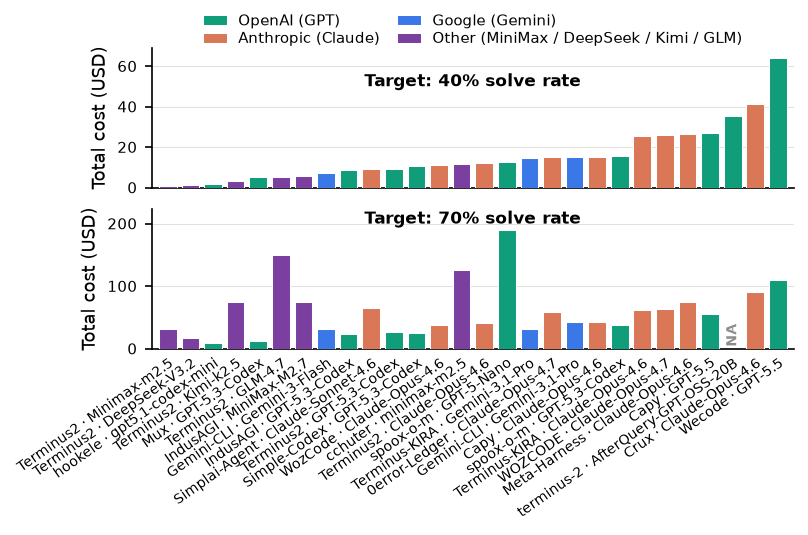

In [2]:
cost_bars("terminal_bench2_priced")

## Figure 2: Arbitrageur improves the cost–performance frontier.

Policies are indexed by the shadow price. For each fold, the allocation at every price is fit on the training problems (`fit`) and scored on the held-out problems (`eval_alloc`); the market baseline is the best single model under the same protocol. Leave-one-out on the Terminal-Bench markets, 10-fold on LiveCodeBench and DeepSWE.

In [3]:
def run_cv(market_name, num_folds, seed=0, verbose=True, estimator="chen"):
    # estimator="chen": pass@k curves from Chen et al.'s unbiased estimator, frozen at the recorded attempts
    market = DATASETS[market_name]
    models, ids, solve_prob, expected_spend, budget = market_curves(market, estimator=estimator)
    # solve_prob[problem, model, budget]: probability that the model solves the problem when given that budget on it
    # expected_spend[model, problem, budget]: expected money actually spent on that budget, since attempts stop at the first success
    num_problems, num_models = solve_prob.shape[:2]
    attempt_price, _ = attempt_prices(load_results(market["base_dir"]), models)  # [problem, model]
    cheapest_first_order = np.argsort(np.asarray(attempt_price, dtype=float).mean(0))
    shadow_prices = shadow_price_grid(solve_prob, budget, num=NUM_SHADOW_PRICES, num_head=NUM_HEAD_PRICES, exact=True)
    num_prices = shadow_prices.size
    arb_solve = np.full((num_prices, num_problems), np.nan)
    arb_revenue = np.zeros((num_prices, num_problems, num_models))  # money reaching each system (Figure 3)
    arb_cheapest_spend = arb_solve.copy()
    best_model_solve = arb_solve.copy()
    best_model_spend = arb_solve.copy()
    test_folds = folds(num_problems, num_folds, seed)
    for fold_idx, test_idx in enumerate(test_folds):
        train_idx = np.setdiff1d(np.arange(num_problems), test_idx)
        # cold start: each fold's sweep starts from zero at the largest shadow price and from its own previous
        # shadow price after that
        _, _, train_allocs, train_orders = fit_frontier(
            solve_prob[train_idx], expected_spend[:, train_idx], budget, shadow_prices, warm_starts=None, sweeps=40
        )
        single_model_solve_train = solve_prob[train_idx].mean(0)  # [model, budget]: each model on its own
        for price_idx, shadow_price in enumerate(shadow_prices):
            # per held-out problem: each model's solve probability and expected spend under the fitted allocation
            solve, spend = cell_outcomes(
                solve_prob[test_idx], list(expected_spend[:, test_idx]), budget, train_allocs[price_idx]
            )
            log_fail = np.log(np.clip(1.0 - solve, 1e-12, 1.0))
            arb_solve[price_idx, test_idx] = 1.0 - np.exp(log_fail.sum(1))
            # deployed in the greedy order, a system is queried, and paid, only when every system before it has failed
            order = np.asarray(train_orders[price_idx])
            prob_reached = np.exp(np.cumsum(log_fail[:, order], 1) - log_fail[:, order])
            arb_revenue[price_idx, test_idx[:, None], order[None, :]] = prob_reached * spend[:, order]
            _, arb_cheapest_spend[price_idx, test_idx] = evaluate_allocation(
                solve_prob[test_idx], expected_spend[:, test_idx], budget, train_allocs[price_idx], cheapest_first_order
            )
            best_model, best_budget_idx = best_single_model(single_model_solve_train, shadow_price, budget)
            best_model_solve[price_idx, test_idx] = solve_prob[test_idx, best_model, best_budget_idx]
            best_model_spend[price_idx, test_idx] = expected_spend[best_model, test_idx, best_budget_idx]
        if verbose and (fold_idx % max(1, len(test_folds) // 10) == 0 or fold_idx == len(test_folds) - 1):
            print(f"  [{market_name}] fold {fold_idx + 1} of {len(test_folds)}", flush=True)

    # pooled over problems: one (solve rate, expected spend per problem) curve per policy
    arb_spend = arb_revenue.sum(2)  # the arbitrageur's spend is what the systems were paid
    arb_curve = (arb_solve.mean(1), arb_spend.mean(1))
    arb_cheapest_curve = (arb_solve.mean(1), arb_cheapest_spend.mean(1))
    best_model_curve = (best_model_solve.mean(1), best_model_spend.mean(1))
    record = market_record(market, in_sample_costs(market, estimator=estimator))
    record["estimator"] = estimator
    solve_rate_grid = record["solve_rate"] / 100.0
    record["arb_cost_cv"] = cost_at_solve_rate(*lower_envelope(*arb_curve), solve_rate_grid) * num_problems
    record["market_cost_cv"] = cost_at_solve_rate(*lower_envelope(*best_model_curve), solve_rate_grid) * num_problems
    record["arb_cheap_cost_cv"] = (
        cost_at_solve_rate(*lower_envelope(*arb_cheapest_curve), solve_rate_grid) * num_problems
    )
    record["cv"] = "leave-one-out" if num_folds == 0 else f"{num_folds}-fold"
    record["n_problems"] = num_problems
    record["cv_lambda"] = shadow_prices  # raw pooled CV curves, per shadow price
    record["cv_arb_solve"], record["cv_arb_spend"] = arb_curve[0], arb_curve[1] * num_problems
    record["cv_market_solve"], record["cv_market_spend"] = best_model_curve[0], best_model_curve[1] * num_problems
    record["cv_arb_cheap_solve"], record["cv_arb_cheap_spend"] = (
        arb_cheapest_curve[0],
        arb_cheapest_curve[1] * num_problems,
    )
    # the per-system split of the spend, read by the revenue-share heatmaps (Figure 3)
    REVENUE_SPLITS[market_name] = dict(
        models=np.array(models), lams=shadow_prices, solve=arb_solve, spend=arb_spend, rev=arb_revenue
    )
    return record

In [4]:
MARKETS = {
    "livecodebench_priced": 10,
    "terminal_bench2_priced": 0,
    "terminal_bench4_priced": 0,
    "deepswe_priced": 10,
}  # folds; 0 = leave-one-out
records = {}
for market_name, num_folds in MARKETS.items():
    records[market_name] = record = run_cv(market_name, num_folds)
    summary_cv(record)

  [livecodebench_priced] fold 1 of 10
  [livecodebench_priced] fold 2 of 10
  [livecodebench_priced] fold 3 of 10
  [livecodebench_priced] fold 4 of 10
  [livecodebench_priced] fold 5 of 10
  [livecodebench_priced] fold 6 of 10
  [livecodebench_priced] fold 7 of 10
  [livecodebench_priced] fold 8 of 10
  [livecodebench_priced] fold 9 of 10
  [livecodebench_priced] fold 10 of 10

== LiveCodeBench (10-fold, 713 problems)
  budget per task ($) | arbitrageur solve rate | best model solve rate
                2e-06 |                  10.6% |                 10.6%
                1e-05 |                  35.7% |                 35.7%
                5e-05 |                  50.9% |                 46.9%
               0.0002 |                  62.3% |                 55.1%
                0.001 |                  72.4% |                 67.5%
                0.005 |                  77.0% |                 71.2%
                 0.02 |                  77.9% |                 71.2%
  [termin

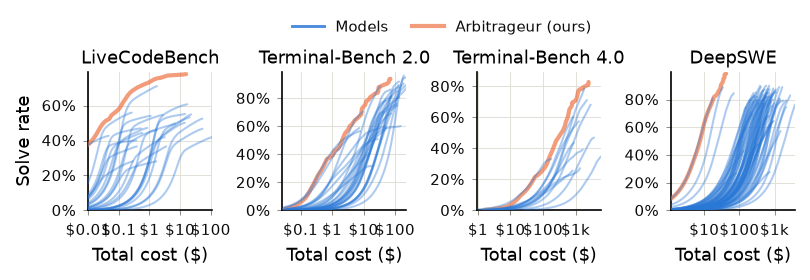

In [5]:
draw_frontiers(list(records.values()), figsize=(5.5, 1.75))

## Figure 3: Revenue spreads across providers as budgets increase.

At every budget, the share of the arbitrageur's spend that reaches each model; the heatmaps show it against the budget per task.



== LiveCodeBench (10-fold, 713 problems)
  budget per task ($) | solve rate | share of the arbitrageur's spend
                2e-06 |      10.6% | Qwen2.5-Coder-Ins-7B 100%
                2e-05 |      40.6% | Qwen2.5-Ins-32B 52%, Qwen2.5-Coder-Ins-7B 48%
               0.0002 |      62.3% | DeepSeek-V3 67%, Qwen2.5-Ins-32B 20%, Qwen2.5-Coder-Ins-7B 8%, others 4%
                0.002 |      75.0% | DeepSeek-V3 58%, Qwen2.5-Ins-72B 8%, Qwen2.5-Ins-32B 8%, Qwen2.5-Coder-Ins-32B 7%, Gemini-Flash-2.0-Exp 5%, others 13%
                 0.02 |      77.9% | Claude-3.5-Sonnet-20241022 34%, Mistral-Large 26%, Claude-3.5-Sonnet-20240620 14%, DeepSeek-V3 11%, others 16%

== Terminal-Bench 2.0 (leave-one-out, 88 problems)
  budget per task ($) | solve rate | share of the arbitrageur's spend
                0.002 |      11.9% | Terminus2 · Minimax-m2.5 100%
                 0.01 |      38.1% | Terminus2 · Minimax-m2.5 80%, Terminus2 · DeepSeek-V3.2 20%
                 0.05 |      61.9% | hooke

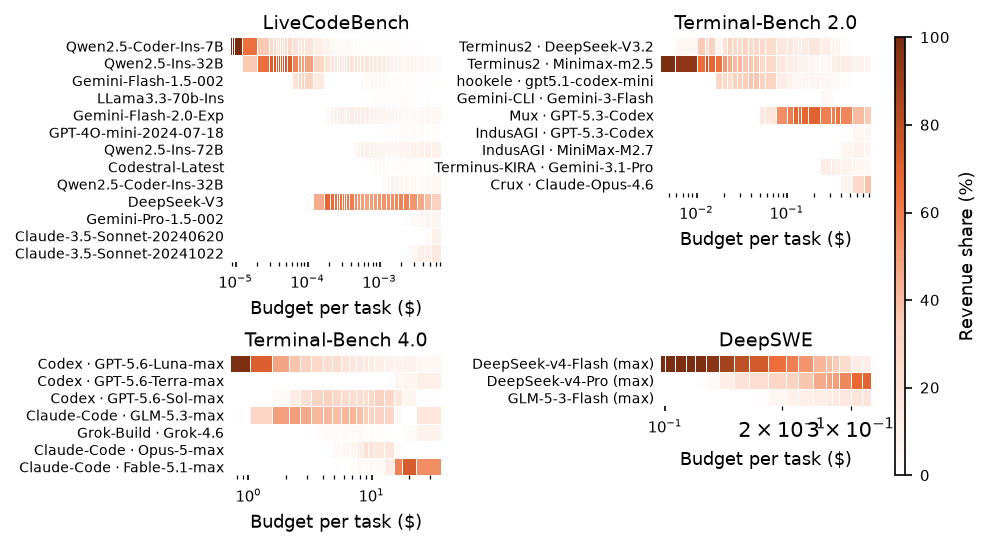

In [6]:
for market_name, record in records.items():
    summary_revenue(REVENUE_SPLITS[market_name], record)  # the per-system split run_cv kept
draw_revenue_shares()

## Figure 4: deployment order

For each fold and shadow price, the expected spend of the fitted allocation on the held-out problems under the greedy order, the cheapest-first order and the best fixed order of the funded models, found by dynamic programming over subsets (`best_order`).

In [7]:
def best_order(solve_prob, expected_spend, budget, alloc, start_orders, dp_max=DP_MAX_FUNDED):
    """Best fixed order of the funded models on the given problems (the optimum of the deployable class):
    exact by the subset DP when <= dp_max models are funded (2^n states), else the best local-search descent
    from each order in `start_orders` (full orders over all models)."""
    num_models = solve_prob.shape[1]
    funded = [model for model in range(num_models) if alloc[model] > 0]
    unfunded = [model for model in range(num_models) if alloc[model] <= 0]
    solve, spend = cell_outcomes(solve_prob, list(expected_spend), budget, alloc)  # [problem, model] under alloc
    fail_funded = np.clip(1.0 - solve, 0.0, 1.0)[:, funded]
    spend_funded = spend[:, funded]
    if len(funded) <= dp_max:
        order_within_funded, _ = best_order_by_dp(fail_funded, spend_funded)
    else:
        log_fail_funded = np.log(np.clip(fail_funded, 1e-12, 1.0))
        position = {model: idx for idx, model in enumerate(funded)}
        order_within_funded, best_cost = None, np.inf
        for start_order in start_orders:
            candidate, cost = best_order_by_local_search(
                log_fail_funded, spend_funded, [position[model] for model in start_order if alloc[model] > 0]
            )
            if cost < best_cost:
                order_within_funded, best_cost = candidate, cost
    return np.array([funded[idx] for idx in order_within_funded] + unfunded)


def spends(solve_prob, expected_spend, budget, alloc, orders):
    """Per-problem solve prob and spend of `alloc` under each deployment order. orders: dict name -> order."""
    spend_by_order = {}
    solve = None
    for order_name in ("greedy", "cheapest", "best"):
        solve, spend_by_order[order_name] = evaluate_allocation(
            solve_prob, expected_spend, budget, alloc, orders[order_name]
        )
    spend_by_order["oracle"] = oracle_per_problem(solve_prob, expected_spend, budget, alloc)
    return solve, spend_by_order


def run_order(market_name, num_folds, seed=0, verbose=True, legend=None):
    market = DATASETS[market_name]
    models, ids, solve_prob, expected_spend, budget = market_curves(
        market, estimator="chen"
    )  # the same frozen pass@k curves as run_cv
    attempt_price, _ = attempt_prices(load_results(market["base_dir"]), models)  # [problem, model]
    num_problems, num_models = solve_prob.shape[:2]
    shadow_prices = shadow_price_grid(solve_prob, budget, num=NUM_SHADOW_PRICES, num_head=NUM_HEAD_PRICES, exact=True)
    num_prices = shadow_prices.size
    in_sample_solve, in_sample_spend, in_sample_allocs, in_sample_orders = fit_frontier(
        solve_prob, expected_spend, budget, shadow_prices
    )
    # in-sample reference: full-data allocation and orders, evaluated on all problems
    cheapest_first_order = np.argsort(attempt_price.mean(0))
    in_sample_spend_by_order = {order_name: np.empty(num_prices) for order_name in ORDER_NAMES}
    num_funded = np.array([(alloc > 0).sum() for alloc in in_sample_allocs])
    for price_idx in range(num_prices):
        orders = dict(
            greedy=in_sample_orders[price_idx],
            cheapest=cheapest_first_order,
            best=best_order(
                solve_prob,
                expected_spend,
                budget,
                in_sample_allocs[price_idx],
                [in_sample_orders[price_idx], cheapest_first_order],
            ),
        )
        _, spend_by_order = spends(solve_prob, expected_spend, budget, in_sample_allocs[price_idx], orders)
        for order_name in ORDER_NAMES:
            in_sample_spend_by_order[order_name][price_idx] = spend_by_order[order_name].mean()
    # cross-validation: held-out results, [shadow price, problem]
    arb_solve = np.full((num_prices, num_problems), np.nan)
    arb_spend_by_order = {order_name: np.full((num_prices, num_problems), np.nan) for order_name in ORDER_NAMES}
    test_folds = folds(num_problems, num_folds, seed)
    for fold_idx, test_idx in enumerate(test_folds):
        train_idx = np.setdiff1d(np.arange(num_problems), test_idx)
        _, _, train_allocs, train_orders = fit_frontier(
            solve_prob[train_idx], expected_spend[:, train_idx], budget, shadow_prices, warm_starts=None, sweeps=40
        )  # cold start, as run_cv
        cheapest_first_order_train = np.argsort(attempt_price[train_idx].mean(0))
        for price_idx in range(num_prices):
            orders = dict(
                greedy=train_orders[price_idx],
                cheapest=cheapest_first_order_train,
                best=best_order(
                    solve_prob[train_idx],
                    expected_spend[:, train_idx],
                    budget,
                    train_allocs[price_idx],
                    [train_orders[price_idx], cheapest_first_order_train],
                ),
            )
            solve, spend_by_order = spends(
                solve_prob[test_idx], expected_spend[:, test_idx], budget, train_allocs[price_idx], orders
            )
            arb_solve[price_idx, test_idx] = solve
            for order_name in ORDER_NAMES:
                arb_spend_by_order[order_name][price_idx, test_idx] = spend_by_order[order_name]
        if verbose and (fold_idx % max(1, len(test_folds) // 10) == 0 or fold_idx == len(test_folds) - 1):
            print(f"  [{market_name}] fold {fold_idx + 1} of {len(test_folds)}", flush=True)
    title = display_title(market)
    record = dict(
        title=title,
        legend=legend or title,
        xlabel=market["xlabel"],
        cv="leave-one-out" if num_folds == 0 else f"{num_folds}-fold",
        n_problems=num_problems,
        n_models=num_models,
        orders=ORDER_NAMES,
        dp_max=DP_MAX_FUNDED,
        lam=shadow_prices,
        n_funded=num_funded,
        solve_in=in_sample_solve,
        solve_cv=arb_solve.mean(1),
    )
    for order_name in ORDER_NAMES:
        record[f"spend_{order_name}_in"] = in_sample_spend_by_order[order_name] * num_problems
        record[f"spend_{order_name}_cv"] = arb_spend_by_order[order_name].mean(1) * num_problems
    return record

  [livecodebench_priced] fold 1 of 10
  [livecodebench_priced] fold 2 of 10
  [livecodebench_priced] fold 3 of 10
  [livecodebench_priced] fold 4 of 10
  [livecodebench_priced] fold 5 of 10
  [livecodebench_priced] fold 6 of 10
  [livecodebench_priced] fold 7 of 10
  [livecodebench_priced] fold 8 of 10
  [livecodebench_priced] fold 9 of 10
  [livecodebench_priced] fold 10 of 10

== LiveCodeBench (10-fold, 713 problems, 24 models)
  solve | #funded | CV spend over best fixed order: greedy cheapest | best over oracle | in-sample: greedy cheapest | best over oracle
   27.5% |   1     |    1.000    1.000         |    1.000    |    1.000    1.000     |    1.000
   38.4% |   2     |    1.000    1.000         |    1.018    |    1.000    1.000     |    1.020
   50.2% |   2     |    1.000    1.000         |    1.042    |    1.000    1.000     |    1.042
   58.5% |   4     |    1.000    1.000         |    1.072    |    1.000    1.000     |    1.083
   69.9% |   5     |    1.004    1.026         

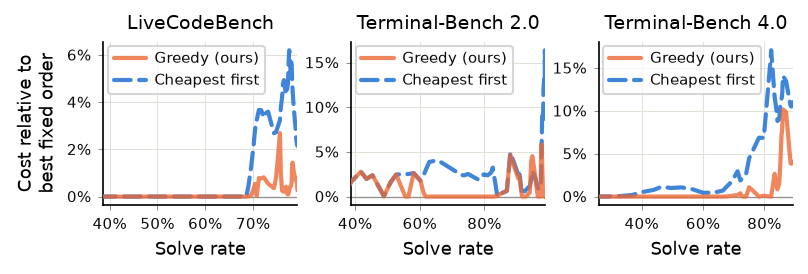

In [8]:
order_records = {}
for market_name, num_folds in MARKETS.items():
    order_records[market_name] = record = run_order(market_name, num_folds, legend=records[market_name]["legend"])
    summary_order(record)
draw_order([order_records[market_name] for market_name in ORDER_FIGURE_MARKETS], figsize=(5.5, 1.95))